# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
install.packages("pheatmap")
library(dplyr)
library(tidyr)
library(purrr)
library(broom)
library(pheatmap)

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Get the bucket name
my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.1.4     ✔ readr   2.1.5
✔ forcats 1.0.0     ✔ stringr 1.5.1
✔ ggplot2 3.5.1     ✔ tibble  3.2.1
✔ purrr   1.0.2     ✔ tidyr   1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

In [47]:
name_of_file_in_bucket <- 'All_SDoH_data_domain_filtered_60.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
sdoh_data  <- read_csv(name_of_file_in_bucket)

name_of_file_in_bucket <- 'adjusted_PRS_scores.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
PRS  <- read_csv(name_of_file_in_bucket) 

sdoh_data<-merge(sdoh_data, PRS, on="person_id", how="left")

character(0)

Rows: 47487 Columns: 76
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (6): SexGender, ancestry_pred, military, healthcare, disabled, sexual_...
dbl  (68): person_id, AIAN, Asian, Black, Mid, Multiple, PI, White, His, rac...
lgl   (1): where_born
date  (1): date_of_birth

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 135205 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adj...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Load and merge data

In [48]:
# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'Case_Control_df.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
Case_Control_df  <- read_csv(name_of_file_in_bucket)

character(0)

Rows: 226674 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [49]:
merged_data<-merge(sdoh_data, Case_Control_df, on="person_id", how="left")

In [50]:
# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'CFA_domain_SDOH_scores'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
CFA_domain_SDOH_scores  <- read_csv(name_of_file_in_bucket)
head(CFA_domain_SDOH_scores)

character(0)

Rows: 47744 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (6): person_id, SDOH, SCC, NBD, ES, HCAU

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


person_id,SDOH,SCC,NBD,ES,HCAU
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1991141,0.8256857,0.4648203,0.2015249,0.6811465,0.5239146
1268583,0.4666934,0.7103707,0.3320261,0.9704993,0.5838638
1783196,0.3542135,0.4258086,0.2765062,0.4838096,0.2055961
2079342,0.2241988,0.5745591,0.3831465,0.5303097,0.5041900
9994702,0.4156849,0.5032595,0.4944437,0.9299568,0.3969629
7341482,0.1715398,0.5858731,0.3440655,0.9514651,0.6796577


In [51]:
merged_data<-merge(merged_data, CFA_domain_SDOH_scores, on="person_id", how="left")
colnames(merged_data)

[1] "person_id"                     "date_of_birth"                
 [3] "AIAN"                          "Asian"                        
 [5] "Black"                         "Mid"                          
 [7] "Multiple"                      "PI"                           
 [9] "White"                         "His"                          
[11] "race_unknown"                  "SexGender"                    
[13] "age_today"                     "ancestry_pred"                
[15] "PC_1"                          "PC_2"                         
[17] "PC_3"                          "PC_4"                         
[19] "PC_5"                          "PC_6"                         
[21] "PC_7"                          "PC_8"                         
[23] "PC_9"                          "PC_10"                        
[25] "PC_11"                         "PC_12"                        
[27] "PC_13"                         "PC_14"                        
[29] "PC_15"                         "PC_16"                        
[31] "where_born"                    "military"                     
[33] "healthcare"                    "disabled"                     
[35] "sexual_orientation"            "LGBTQIA"                      
[37] "min_date"                      "max_date"                     
[39] "ehr_length"                    "relative_health"              
[41] "record_depth"                  "visit_frequency"              
[43] "age"                           "record_depth_winsorized"      
[45] "visit_frequency_winsorized"    "education"                    
[47] "employment"                    "income"                       
[49] "home_own"                      "number_living"                
[51] "median_adjusted_income"        "number_living_adjusted_income"
[53] "income_adjusted_both"          "health_literacy"              
[55] "housing_quality"               "housing_instability"          
[57] "food_insecurity"               "Walkability"                  
[59] "loneliness"                    "crime_saftey"                 
[61] "npd_scale"                     "nsd_scale"                    
[63] "discrimination"                "health_discrim"               
[65] "social_cohesion"               "stress"                       
[67] "social_support"                "spirituality"                 
[69] "health_coverage"               "health_care_use"              
[71] "delayed_care"                  "afford_care"                  
[73] "worried_pay"                   "respect"                      
[75] "housing_type"                  "per_poverty_threshold"        
[77] "Asthma_adjusted_score"         "Afib_adjusted_score"          
[79] "BreastC_adjusted_score"        "CKD_adjusted_score"           
[81] "CHD_adjusted_score"            "HyperC_adjusted_score"        
[83] "ProstateC_adjusted_score"      "t1d_adjusted_score"           
[85] "t2d_adjusted_score"            "Asthma"                       
[87] "Afib"                          "BreastC"                      
[89] "CKD"                           "CHD"                          
[91] "HyperC"                        "ProstateC"                    
[93] "t2d"                           "t1d"                          
[95] "SDOH"                          "SCC"                          
[97] "NBD"                           "ES"                           
[99] "HCAU"

In [52]:
merged_data$per_poverty_threshold<-1-merged_data$per_poverty_threshold
merged_data$education<-1-merged_data$education

In [53]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

## Set up lists

In [54]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")
domains<-c("SDOH", "SCC", "NBD", "ES", "HCAU", "education")

# Regressions

## Models

In [55]:
#install.packages("pROC")

In [56]:
library(dplyr)
library(broom)
library(pROC)

# Model labels
models <- c("Base", "Genetic", "Social", "Joint", "Interaction")

# Function to generate formulas for disease-domain pairs
generate_formulas <- function(disease, domain) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease == "CKD" || disease == "t1d") {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease == "BreastC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }
  if (disease == "ProstateC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  # Return all 5 models
  list(
    as.formula(paste(disease, "~", base)),
    as.formula(paste(disease, "~", paste(c(base, score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, domain), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, score, domain), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, score, domain, paste0(score, " * ", domain)), collapse = " + ")))
  )
}


## Auc

In [57]:
# Updated function to fit models and extract results
fit_and_extract <- function(formulas, disease, domain, models, data) {
  map2_dfr(formulas, models, ~ {
      
    # Filter data based on disease-specific sex/gender logic
    filtered_data <- data
    
    if (disease %in% c("CKD", "t1d")) {
      filtered_data <- filtered_data %>% filter(SexGenderSGM == 0)
    }
    if (disease == "BreastC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_male == 0)
    }
    if (disease == "ProstateC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_female == 0)
    }

    # Remove rows with missing values in any variables used in the formula
    vars_in_model <- all.vars(.x)
    filtered_data <- filtered_data %>% filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    # Fit the model
    model <- glm(.x, data = filtered_data, family = binomial(link = "logit"))
    
    # Calculate predictions and actual values for AUC
    preds <- predict(model, type = "response")
    actuals <- model$y
    
    # Calculate AUC and 95% CI
    if (length(unique(actuals)) > 1) {
      roc_obj <- roc(actuals, preds, quiet = TRUE)  # ROC object
      auc <- as.numeric(roc_obj$auc)  # AUC value
      auc_ci <- ci.auc(roc_obj)  # AUC confidence interval
    } else {
      auc <- NA
      auc_ci <- c(NA, NA, NA)  # Placeholder for CI
    }
    
    # Model coefficients
    tidy(model) %>%
      mutate(
        Disease = disease,
        Domain = domain,
        Model = .y,
        AUC = auc,
        AUC_CI_Lower = auc_ci[1],
        AUC_CI_Upper = auc_ci[3]
      )
  })
}

# Step 1: Generate combinations of diseases and domains
combinations <- expand_grid(
  disease = unlist(diseases),
  domain = domains
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas = list(generate_formulas(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, models, merged_data))
  ) %>%
  ungroup() %>%
  select(model_results) %>%
  unnest(model_results) 
 

# Step 3: Clean and arrange results
results <- results %>%
  select(Disease, Domain, Model, term, estimate, std.error, statistic, p.value, AUC, AUC_CI_Lower, AUC_CI_Upper)

results <- results %>%
  mutate(Log_Odds = exp(estimate))  # Rename estimates for clarity

# Print results
head(results)



Warning message:
“There were 30 warnings in `mutate()`.
The first warning was:
ℹ In argument: `model_results = list(fit_and_extract(formulas, disease, domain,
  models, merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 29 remaining warnings.”


Disease,Domain,Model,term,estimate,std.error,statistic,p.value,AUC,AUC_CI_Lower,AUC_CI_Upper,Log_Odds
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,SDOH,Base,(Intercept),-0.74926518,0.0777541733,-9.636334,5.615783e-22,0.835201,0.8282173,0.8421848,0.47271379
Asthma,SDOH,Base,age,-0.01330028,0.0013806533,-9.633325,5.782745e-22,0.835201,0.8282173,0.8421848,0.98678778
Asthma,SDOH,Base,record_depth,0.01373301,0.0003888592,35.316150,3.318651e-273,0.835201,0.8282173,0.8421848,1.01382774
Asthma,SDOH,Base,visit_frequency,-2.98589114,1.3998228831,-2.133049,3.292069e-02,0.835201,0.8282173,0.8421848,0.05049449
Asthma,SDOH,Base,SexGenderCis_male,-0.75791963,0.0476739529,-15.897982,6.543926e-57,0.835201,0.8282173,0.8421848,0.46864036
Asthma,SDOH,Base,SexGenderSGM,-0.19112371,0.1454738382,-1.313801,1.889131e-01,0.835201,0.8282173,0.8421848,0.82603039


## Primary heatmap

In [58]:
all_coefficients <- results %>%
  filter(
    Model == "Social" & term %in% c("SDOH", "SCC", "NBD", "ES", "HCAU", "education", "per_poverty_threshold") |
      (Model == "Genetic" & str_detect(term, "_adjusted_score")) |  # PRS 
      (Model == "Interaction" & str_detect(term, "_adjusted_score:"))
  ) %>%
  mutate(
    term = case_when(
      # If term ends with "_adjusted_score", rename to "PRS"
      str_detect(term, "_adjusted_score$") ~ "PRS",
      # If term contains "_adjusted_score:" replace with "PRS*"
      str_detect(term, "_adjusted_score:") ~ str_replace(term, ".*_adjusted_score:", "PRS*"),
      # Keep other terms as is
      TRUE ~ term
    )
  ) %>%
  select(Disease, Domain, term, p.value, std.error, Effect_Size = estimate, Log_Odds) %>%  # Standardize column names
  filter(
    (term == "PRS" & Domain == "SDOH") |  # Only include PRS when Domain == "SDOH"
    (term == "age" & Domain == "SDOH") |  # Only include age when Domain == "SDOH"
    term %in% c("SDOH", "SCC", "NBD", "ES", "HCAU", "education", "per_poverty_threshold",
                "PRS*SDOH", "PRS*SCC", "PRS*NBD", "PRS*ES", "PRS*HCAU", "PRS*education",
               "PRS*per_poverty_threshold")  # Include other relevant terms
  )


In [59]:
x_axis_order <- c("SDOH", "SCC", "NBD", "ES", "HCAU", "education")


# Step 1: Ensure unique values for each Disease and term combination
all_coefficients_clean <- all_coefficients %>%
  group_by(Disease, term) %>%
  summarize(Effect_Size = mean(Effect_Size, na.rm = TRUE), .groups = "drop")  # Aggregate duplicates by averaging

# Step 2: Reshape data for clustering
heatmap_data <- all_coefficients_clean %>%
  pivot_wider(
    names_from = term,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = Effect_Size  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames

# Ensure all values are numeric and handle NA values
heatmap_data <- heatmap_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
heatmap_data[is.na(heatmap_data)] <- 0  # Replace NA values with 0 (or another placeholder)


heatmap_data <- heatmap_data %>%
  select(all_of(x_axis_order))  # Reorder columns to match the specified list


# Step 2: Verify heatmap data
print(heatmap_data)


                SDOH        SCC        NBD         ES       HCAU  education
Afib       0.3331496  0.5913501  0.1941524  0.5276918  1.0496710  0.2533836
Asthma     0.9512093  1.8291623  0.4908285  1.2798366  1.8708516  0.5880118
BreastC   -0.4852170 -0.5842031 -0.5709820 -0.8766126 -0.5090716 -0.4269716
CHD        1.0688639  0.8048800  0.3659400  1.1426968  1.2016208  0.7658760
CKD        1.1469323  1.5125224  1.0756539  2.3235529  1.4894816  0.9808057
ProstateC -0.9116261 -1.5036986 -1.1781748 -2.6577344 -0.6534117 -1.2051217
t1d        1.5145574  1.0918286  1.4510756  1.9254857  1.9666944  1.3897762
t2d        2.1822625  1.6946582  1.8724224  2.9414607  2.2964319  1.9404020


In [60]:
# Step 1: Ensure unique values for each Disease and term combination
all_coefficients_clean <- all_coefficients %>%
  group_by(Disease, term) %>%
  summarize(
    p_value = mean(p.value, na.rm = TRUE),  # Aggregate p-values for consistency
    .groups = "drop"
  ) 

# Step 2: Reshape data for clustering
pvalue_data <- all_coefficients_clean %>%
  pivot_wider(
    names_from = term,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = p_value  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames


# Ensure all values are numeric and handle NA values
pvalue_data <- pvalue_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
pvalue_data[is.na(pvalue_data)] <- 0  # Replace NA values with 0 (or another placeholder)
pvalue_data[pvalue_data>0.05/54] <- 0  # Replace NA values with 0 (or another placeholder)


pvalue_data <- pvalue_data %>%
  select(all_of(x_axis_order))  # Reorder columns to match the specified list

pvalue_data

,SDOH,SCC,NBD,ES,HCAU,education
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Afib,0.000000e+00,3.590028e-04,0.000000e+00,5.172332e-05,5.593779e-12,0.000000e+00
Asthma,7.074615e-14,1.068236e-28,2.926805e-04,5.371079e-25,3.919647e-38,2.845143e-11
BreastC,1.453161e-04,3.982961e-04,4.370891e-05,8.650458e-11,5.553198e-04,2.305432e-06
CHD,8.591932e-33,1.916886e-11,2.454977e-04,4.924508e-34,4.006049e-27,5.102540e-36
CKD,1.301362e-18,5.143166e-18,1.246558e-13,9.009644e-65,5.317933e-20,2.008735e-28
ProstateC,2.139313e-06,1.373374e-09,2.203715e-08,1.366090e-24,0.000000e+00,2.712210e-18
t1d,7.476445e-10,6.831876e-04,2.213193e-08,5.919625e-18,2.802174e-12,1.684336e-17
t2d,2.460007e-96,2.443508e-38,3.177480e-61,1.442956e-169,6.135036e-78,5.319381e-145


In [61]:
# Ensure both matrices have the same structure
if (!all(dim(heatmap_data) == dim(pvalue_data))) {
  stop("Error: Dimensions of heatmap_data and pvalue_data do not match.")
}

# Convert pvalue_data to logical mask (TRUE for p-value == 0)
mask <- pvalue_data == 0

# Apply the mask to heatmap_data: Set values to NA where p-value is 0
heatmap_data_labels <- round(heatmap_data, 2)
heatmap_data_labels[mask] <- ""

In [62]:
heatmap_data

,SDOH,SCC,NBD,ES,HCAU,education
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Afib,0.3331496,0.5913501,0.1941524,0.5276918,1.0496710,0.2533836
Asthma,0.9512093,1.8291623,0.4908285,1.2798366,1.8708516,0.5880118
BreastC,-0.4852170,-0.5842031,-0.5709820,-0.8766126,-0.5090716,-0.4269716
CHD,1.0688639,0.8048800,0.3659400,1.1426968,1.2016208,0.7658760
CKD,1.1469323,1.5125224,1.0756539,2.3235529,1.4894816,0.9808057
ProstateC,-0.9116261,-1.5036986,-1.1781748,-2.6577344,-0.6534117,-1.2051217
t1d,1.5145574,1.0918286,1.4510756,1.9254857,1.9666944,1.3897762
t2d,2.1822625,1.6946582,1.8724224,2.9414607,2.2964319,1.9404020


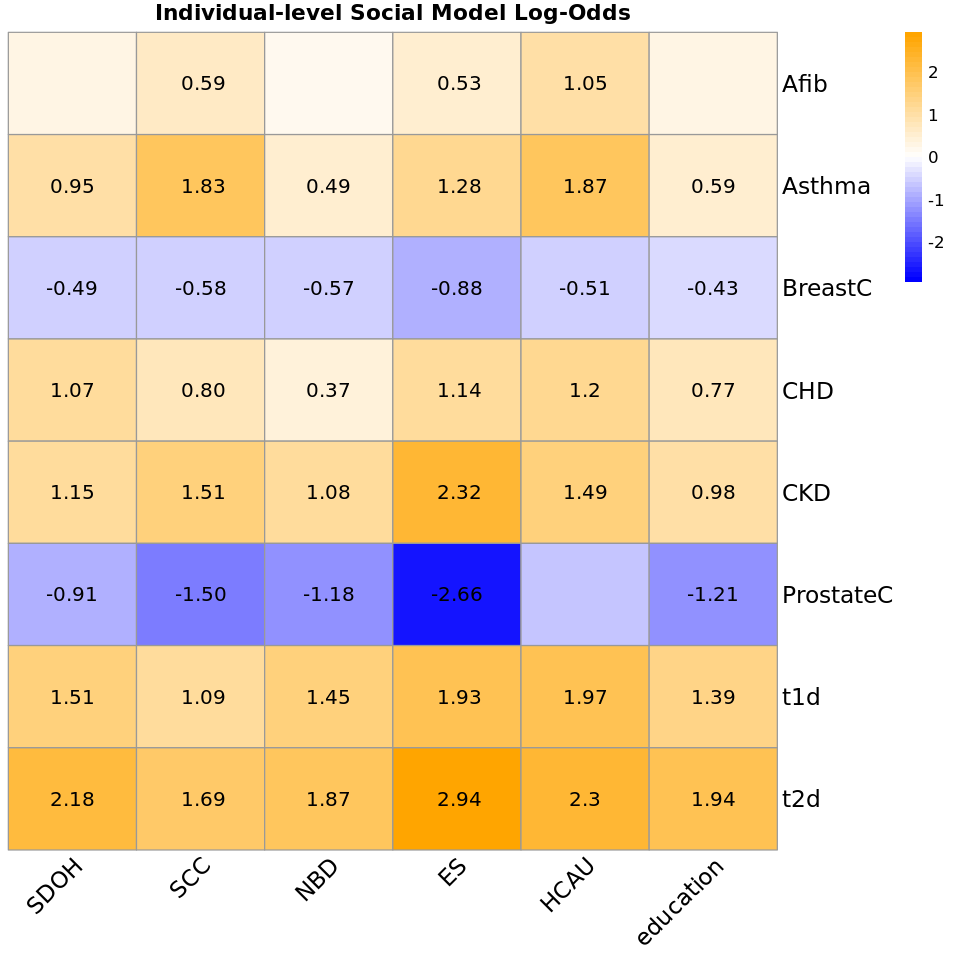

In [63]:
# Step 2: Define a diverging color scale centered at 0
max_abs_value <- max(abs(heatmap_data), na.rm = TRUE)  # Maximum absolute value for symmetric scaling
breaks <- seq(-max_abs_value, max_abs_value, length.out = 51)  # Create breaks for the scale

color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors

# Step 3: Create a clustering heatmap
map<-pheatmap(
  heatmap_data,
  color = color_palette,  # Diverging color scale
  breaks = breaks,  # Center scale at 0
  cluster_rows = TRUE,  # Cluster diseases
  cluster_cols = FALSE,  # Do not cluster columns (respect custom order)
  main = "Individual-level Social Model Log-Odds",
  fontsize_row = 14,  # Font size for row labels
  fontsize_col = 14,  # Font size for column labels
  display_numbers = heatmap_data_labels,  # Show effect sizes in cells
  number_color = "black",  # Color of the numbers
  number_format = "%.2f",  # Format for numbers in cells
  fontsize_number = 12,
  height = 1,  # Increase vertical size of the heatmap
  width=3,
   angle_col = 45  
)

options(repr.plot.width = 8, repr.plot.height = 8)  # Set width and height

# Save the plot (optional)
ggsave("individual_sdoh_coefficients_heatmap.png", plot = map, width = 8, height = 8, dpi = 300)

## Interaction Heatmap

In [64]:
x_axis_order <- c("PRS*SDOH", "PRS*SCC", "PRS*NBD", "PRS*ES", "PRS*HCAU", "PRS*education")


# Step 1: Ensure unique values for each Disease and term combination
all_coefficients_clean <- all_coefficients %>%
  group_by(Disease, term) %>%
  summarize(Effect_Size = mean(Effect_Size, na.rm = TRUE), .groups = "drop")  # Aggregate duplicates by averaging

# Step 2: Reshape data for clustering
heatmap_data <- all_coefficients_clean %>%
  pivot_wider(
    names_from = term,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = Effect_Size  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames

# Ensure all values are numeric and handle NA values
heatmap_data <- heatmap_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
heatmap_data[is.na(heatmap_data)] <- 0  # Replace NA values with 0 (or another placeholder)


heatmap_data <- heatmap_data %>%
  select(all_of(x_axis_order))  # Reorder columns to match the specified list


# Step 2: Verify heatmap data
print(heatmap_data)

            PRS*SDOH    PRS*SCC    PRS*NBD     PRS*ES   PRS*HCAU PRS*education
Afib      -0.2399592 -1.1325668 -0.5278244 -4.0802101 -3.3995665    -0.2222384
Asthma    -1.7536198 -0.7534277 -1.5047743 -2.6347029 -1.4069244    -1.3459585
BreastC   -1.2595249  3.4866778  0.9817898  0.8431699  1.9927878    -0.5087702
CHD        0.8213916 -2.5452466 -1.2304391 -1.8925936 -1.2085238     0.6429424
CKD       -1.2078179  1.8216377 -1.0944300 -3.5627808 -0.1733091    -0.9625483
ProstateC  0.3972999 -1.1030631 -1.0499098  3.3769690 -2.9766009     1.1330235
t1d       -1.4664505 -1.6972105 -2.5930905 -2.6909368 -2.2840135    -1.7173507
t2d       -2.1835277 -1.1861876 -2.6283856 -2.8432076 -2.2108022    -1.7564702


In [65]:
# Step 1: Ensure unique values for each Disease and term combination
all_coefficients_clean <- all_coefficients %>%
  group_by(Disease, term) %>%
  summarize(
    p_value = mean(p.value, na.rm = TRUE),  # Aggregate p-values for consistency
    .groups = "drop"
  ) 

# Step 2: Reshape data for clustering
pvalue_data <- all_coefficients_clean %>%
  pivot_wider(
    names_from = term,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = p_value  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames


# Ensure all values are numeric and handle NA values
pvalue_data <- pvalue_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
pvalue_data[is.na(pvalue_data)] <- 0  # Replace NA values with 0 (or another placeholder)
pvalue_data<-ifelse(pvalue_data<0.05/54, "**", ifelse(pvalue_data<0.05, "*", " "))
pvalue_data <- as.data.frame(pvalue_data)


pvalue_data <- pvalue_data %>%
  select(all_of(x_axis_order))  # Reorder columns to match the specified list

pvalue_data

,PRS*SDOH,PRS*SCC,PRS*NBD,PRS*ES,PRS*HCAU,PRS*education
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Afib,,,,**,*,
Asthma,,,,*,,
BreastC,,*,,,,
CHD,,*,,*,,
CKD,,,,*,,
ProstateC,,,,,,
t1d,,,,,,
t2d,*,,*,*,,*


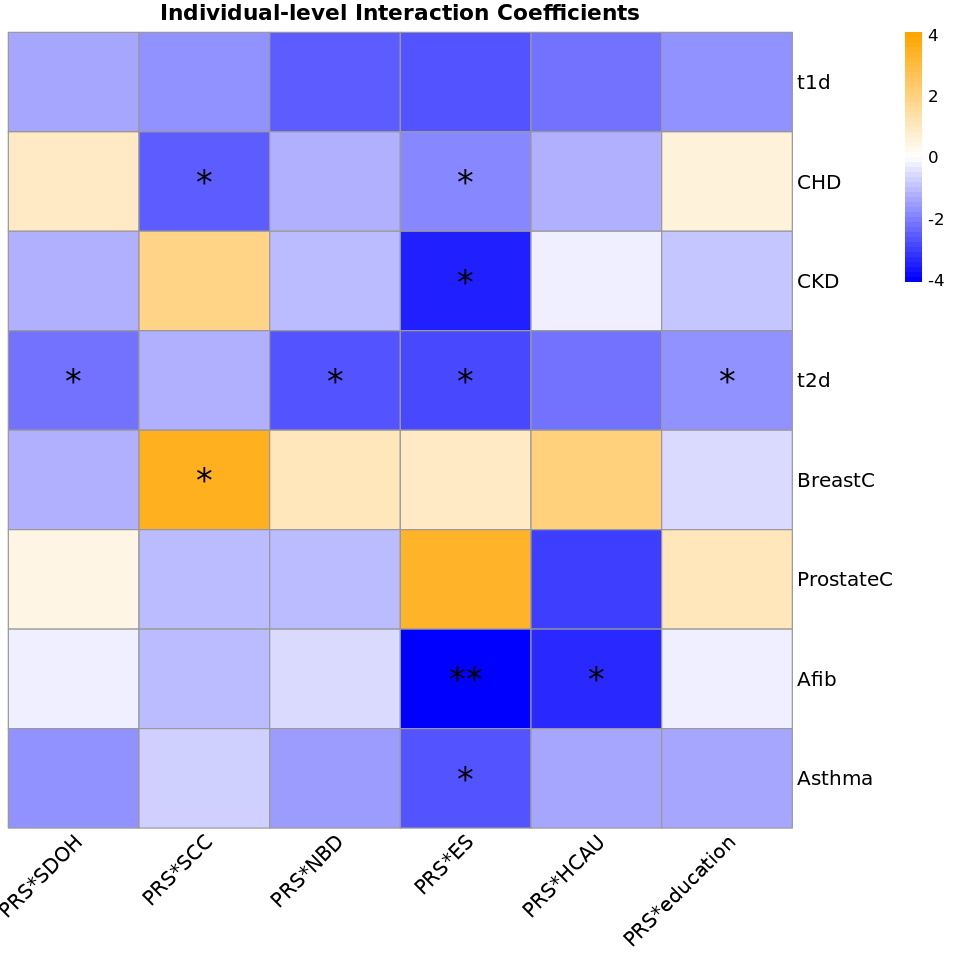

In [69]:
# Step 2: Define a diverging color scale centered at 0
max_abs_value <- max(abs(heatmap_data), na.rm = TRUE)  # Maximum absolute value for symmetric scaling
breaks <- seq(-max_abs_value, max_abs_value, length.out = 51)  # Create breaks for the scale

color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors

desired_order <- c("t1d", "CHD", "CKD", "t2d", "BreastC", "ProstateC", "Afib", "Asthma") 
rownames(heatmap_data) <- factor(rownames(heatmap_data), levels = desired_order)
# Ensure rownames match desired order
heatmap_data <- heatmap_data[desired_order, , drop = FALSE]  
pvalue_data <- pvalue_data[desired_order, , drop = FALSE]  


# Step 3: Create a clustering heatmap
map<-pheatmap(
  heatmap_data,
  color = color_palette,  # Diverging color scale
  breaks = breaks,  # Center scale at 0
  cluster_rows = FALSE,  # Cluster diseases
  cluster_cols = FALSE,  # Do not cluster columns (respect custom order)
  main = "Individual-level Interaction Coefficients",
  fontsize_row = 12,  # Font size for row labels
  fontsize_col = 12,  # Font size for column labels
  display_numbers = pvalue_data,  # Show effect sizes in cells
  number_color = "black",  # Color of the numbers
  number_format = "%.2f",  # Format for numbers in cells
  fontsize_number = 20,  # ✅ Increase size of the numbers in cells
  height = 1,  # Increase vertical size of the heatmap
  width=3,
   angle_col = 45  
)

options(repr.plot.width = 8, repr.plot.height = 8)  # Set width and height

# Save the plot (optional)
ggsave("individual_sdoh_interaction_heatmap.png", plot = map, width = 8, height = 8, dpi = 300)

# Investigate Base Model

In [26]:
all_coefficients <- results %>%
  filter(
    Model == "Base" & term %in% c("age", "SexGenderCis_male", "SexGenderSGM",
                                 "visit_frequency", "record_depth"))  

all_coefficients

Disease,Domain,Model,term,estimate,std.error,statistic,p.value,AUC,AUC_CI_Lower,AUC_CI_Upper,Log_Odds
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,SDOH,Base,age,-0.01330028,0.0013806533,-9.633325,5.782745e-22,0.835201,0.8282173,0.8421848,0.98678778
Asthma,SDOH,Base,record_depth,0.01373301,0.0003888592,35.316150,3.318651e-273,0.835201,0.8282173,0.8421848,1.01382774
Asthma,SDOH,Base,visit_frequency,-2.98589114,1.3998228831,-2.133049,3.292069e-02,0.835201,0.8282173,0.8421848,0.05049449
Asthma,SDOH,Base,SexGenderCis_male,-0.75791963,0.0476739529,-15.897982,6.543926e-57,0.835201,0.8282173,0.8421848,0.46864036
Asthma,SDOH,Base,SexGenderSGM,-0.19112371,0.1454738382,-1.313801,1.889131e-01,0.835201,0.8282173,0.8421848,0.82603039
Asthma,SCC,Base,age,-0.01330028,0.0013806533,-9.633325,5.782745e-22,0.835201,0.8282173,0.8421848,0.98678778
Asthma,SCC,Base,record_depth,0.01373301,0.0003888592,35.316150,3.318651e-273,0.835201,0.8282173,0.8421848,1.01382774
Asthma,SCC,Base,visit_frequency,-2.98589114,1.3998228831,-2.133049,3.292069e-02,0.835201,0.8282173,0.8421848,0.05049449
Asthma,SCC,Base,SexGenderCis_male,-0.75791963,0.0476739529,-15.897982,6.543926e-57,0.835201,0.8282173,0.8421848,0.46864036


In [27]:
# Step 1: Ensure unique values for each Disease and term combination
all_coefficients_clean <- all_coefficients %>%
  group_by(Disease, term) %>%
  summarize(Effect_Size = mean(estimate, na.rm = TRUE), .groups = "drop")  # Aggregate duplicates by averaging

# Step 2: Reshape data for clustering
heatmap_data <- all_coefficients_clean %>%
  pivot_wider(
    names_from = term,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = Effect_Size  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames


# Step 2: Verify heatmap data
print(heatmap_data)

          SexGenderCis_male SexGenderSGM         age  record_depth
Afib            0.643229957    0.6907416  0.04995160 -9.268720e-04
Asthma         -0.757919632   -0.1911237 -0.01330028  1.373301e-02
BreastC                  NA   -0.7630230  0.05256139  5.858998e-04
CHD             0.883816647    0.5819817  0.06969197  1.359919e-03
CKD             0.009437092           NA  0.11295555  8.920640e-04
ProstateC                NA   -0.2678308  0.05722607 -1.461027e-03
t1d             0.614310041           NA -0.01198555  1.458256e-05
t2d             0.384147494    0.4066277  0.02797473 -7.621143e-04
          visit_frequency
Afib             5.024484
Asthma          -2.985891
BreastC          3.539110
CHD              4.412340
CKD              8.923269
ProstateC        4.157088
t1d              4.188200
t2d              8.563425


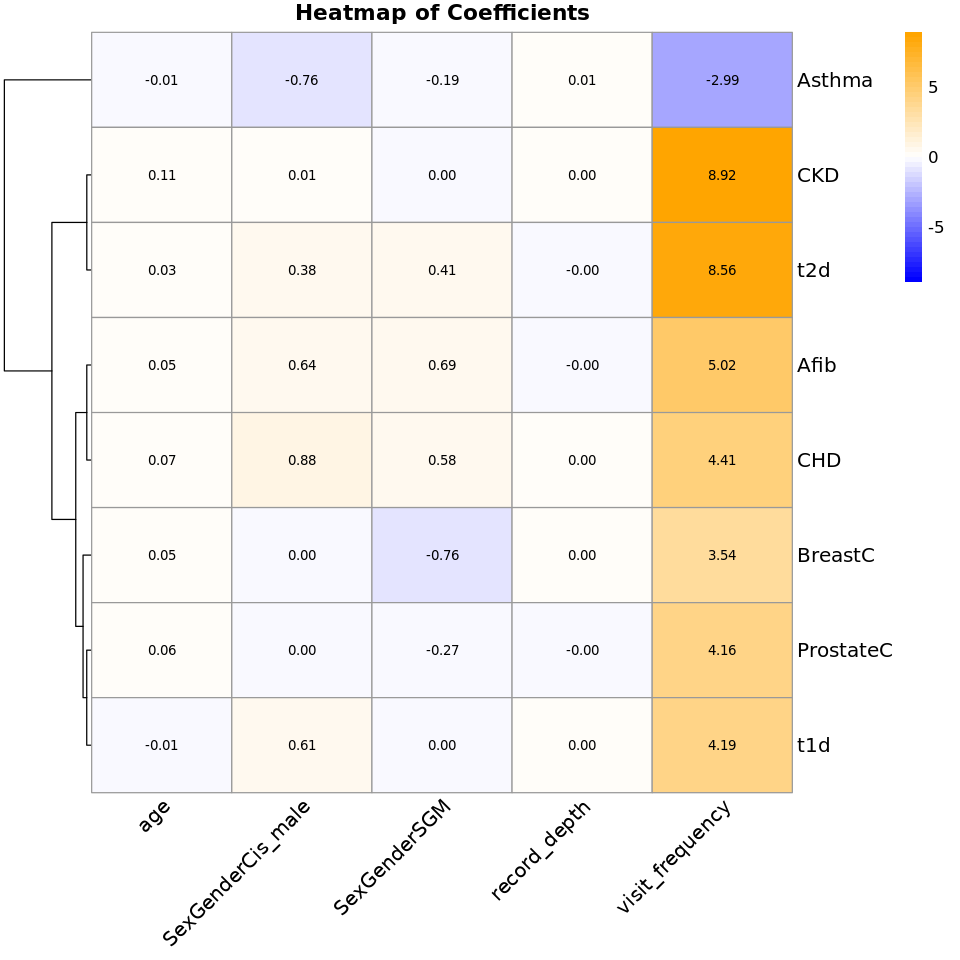

In [28]:
x_axis_order <- c("age", "SexGenderCis_male", "SexGenderSGM", "record_depth", "visit_frequency")


# Ensure all values are numeric and handle NA values
heatmap_data <- heatmap_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
heatmap_data[is.na(heatmap_data)] <- 0  # Replace NA values with 0 (or another placeholder)


heatmap_data <- heatmap_data %>%
  select(all_of(x_axis_order))  # Reorder columns to match the specified list


# Step 2: Define a diverging color scale centered at 0
max_abs_value <- max(abs(heatmap_data), na.rm = TRUE)  # Maximum absolute value for symmetric scaling
breaks <- seq(-max_abs_value, max_abs_value, length.out = 51)  # Create breaks for the scale

color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors


# Step 3: Create a clustering heatmap
map<-pheatmap(
  heatmap_data,
  color = color_palette,  # Diverging color scale
  breaks = breaks,  # Center scale at 0
  cluster_rows = TRUE,  # Cluster diseases
  cluster_cols = FALSE,  # Do not cluster columns (respect custom order)
  main = "Heatmap of Coefficients",
  fontsize_row = 12,  # Font size for row labels
  fontsize_col = 12,  # Font size for column labels
  display_numbers = TRUE,  # Show effect sizes in cells
  number_color = "black",  # Color of the numbers
  number_format = "%.2f",  # Format for numbers in cells
  height = 1,  # Increase vertical size of the heatmap
  width=3,
   angle_col = 45  
)

# Area-level 

In [29]:
# This query represents dataset "zip_ses_all" for domain "zip_code_socioeconomic" and was generated for All of Us Controlled Tier Dataset v7
dataset_95276326_zip_code_socioeconomic_sql <- paste("
    SELECT
        observation.person_id,
        observation.observation_datetime,
        zip_code.zip3_as_string as zip_code,
        zip_code.fraction_assisted_income as assisted_income,
        zip_code.fraction_high_school_edu as high_school_education,
        zip_code.median_income,
        zip_code.fraction_no_health_ins as no_health_insurance,
        zip_code.fraction_poverty as poverty,
        zip_code.fraction_vacant_housing as vacant_housing,
        zip_code.deprivation_index,
        zip_code.acs as american_community_survey_year 
    FROM
        `zip3_ses_map` zip_code 
    JOIN
        `observation` observation 
            ON CAST(SUBSTR(observation.value_as_string, 0, STRPOS(observation.value_as_string, '*') - 1) AS INT64) = zip_code.zip3  
    WHERE
        observation.PERSON_ID IN (SELECT
            distinct person_id  
        FROM
            `cb_search_person` cb_search_person  
        WHERE
            cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_whole_genome_variant = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_ehr_data = 1 ) ) 
        AND observation_source_concept_id = 1585250 
        AND observation.value_as_string NOT LIKE 'Res%'", sep="")

# Formulate a Cloud Storage destination path for the data exported from BigQuery.
# NOTE: By default data exported multiple times on the same day will overwrite older copies.
#       But data exported on a different days will write to a new location so that historical
#       copies can be kept as the dataset definition is changed.
zip_code_socioeconomic_95276326_path <- file.path(
  Sys.getenv("WORKSPACE_BUCKET"),
  "bq_exports",
  Sys.getenv("OWNER_EMAIL"),
  strftime(lubridate::now(), "%Y%m%d"),  # Comment out this line if you want the export to always overwrite.
  "zip_code_socioeconomic_95276326",
  "zip_code_socioeconomic_95276326_*.csv")
message(str_glue('The data will be written to {zip_code_socioeconomic_95276326_path}. Use this path when reading ',
                 'the data into your notebooks in the future.'))

# Perform the query and export the dataset to Cloud Storage as CSV files.
# NOTE: You only need to run `bq_table_save` once. After that, you can
#       just read data from the CSVs in Cloud Storage.
bq_table_save(
  bq_dataset_query(Sys.getenv("WORKSPACE_CDR"), dataset_95276326_zip_code_socioeconomic_sql, billing = Sys.getenv("GOOGLE_PROJECT")),
  zip_code_socioeconomic_95276326_path,
  destination_format = "CSV")


# Read the data directly from Cloud Storage into memory.
# NOTE: Alternatively you can `gsutil -m cp {zip_code_socioeconomic_95276326_path}` to copy these files
#       to the Jupyter disk.
read_bq_export_from_workspace_bucket <- function(export_path) {
  col_types <- cols(zip3_as_string = col_character())
  bind_rows(
    map(system2('gsutil', args = c('ls', export_path), stdout = TRUE, stderr = TRUE),
        function(csv) {
          message(str_glue('Loading {csv}.'))
          chunk <- read_csv(pipe(str_glue('gsutil cat {csv}')), col_types = col_types, show_col_types = FALSE)
          if (is.null(col_types)) {
            col_types <- spec(chunk)
          }
          chunk
        }))
}
zip_code_socioeconomic_df <- read_bq_export_from_workspace_bucket(zip_code_socioeconomic_95276326_path)


The data will be written to gs://fc-secure-784622b3-a3b0-42a1-a555-372ab8841bd6/bq_exports/micah_hysong@researchallofus.org/20250415/zip_code_socioeconomic_95276326/zip_code_socioeconomic_95276326_*.csv. Use this path when reading the data into your notebooks in the future.

Loading gs://fc-secure-784622b3-a3b0-42a1-a555-372ab8841bd6/bq_exports/micah_hysong@researchallofus.org/20250415/zip_code_socioeconomic_95276326/zip_code_socioeconomic_95276326_000000000000.csv.

Warning message:
“The following named parsers don't match the column names: zip3_as_string”


In [30]:
# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'Demographic_and_ancestry_covariates.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
demo  <- read_csv(name_of_file_in_bucket)

character(0)

Rows: 135205 Columns: 47
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, income, education, where_born, military...
dbl  (27): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [31]:
merged_data<-merge(zip_code_socioeconomic_df, demo, on="person_id", how="left")
merged_data<-merge(merged_data, Case_Control_df, on="person_id", how="left")
merged_data<-merge(merged_data, PRS, on="person_id", how="left")
merged_data<-rename(merged_data, age = age_at_last_event)
colnames(merged_data)

[1] "person_id"                      "observation_datetime"          
 [3] "zip_code"                       "assisted_income"               
 [5] "high_school_education"          "median_income"                 
 [7] "no_health_insurance"            "poverty"                       
 [9] "vacant_housing"                 "deprivation_index"             
[11] "american_community_survey_year" "date_of_birth"                 
[13] "AIAN"                           "Asian"                         
[15] "Black"                          "Mid"                           
[17] "Multiple"                       "PI"                            
[19] "White"                          "His"                           
[21] "race_unknown"                   "SexGender"                     
[23] "age_today"                      "ancestry_pred"                 
[25] "PC_1"                           "PC_2"                          
[27] "PC_3"                           "PC_4"                          
[29] "PC_5"                           "PC_6"                          
[31] "PC_7"                           "PC_8"                          
[33] "PC_9"                           "PC_10"                         
[35] "PC_11"                          "PC_12"                         
[37] "PC_13"                          "PC_14"                         
[39] "PC_15"                          "PC_16"                         
[41] "income"                         "education"                     
[43] "where_born"                     "military"                      
[45] "healthcare"                     "disabled"                      
[47] "sexual_orientation"             "LGBTQIA"                       
[49] "min_date"                       "max_date"                      
[51] "ehr_length"                     "relative_health"               
[53] "record_depth"                   "visit_frequency"               
[55] "age"                            "record_depth_winsorized"       
[57] "visit_frequency_winsorized"     "Asthma"                        
[59] "Afib"                           "BreastC"                       
[61] "CKD"                            "CHD"                           
[63] "HyperC"                         "ProstateC"                     
[65] "t2d"                            "t1d"                           
[67] "Asthma_adjusted_score"          "Afib_adjusted_score"           
[69] "BreastC_adjusted_score"         "CKD_adjusted_score"            
[71] "CHD_adjusted_score"             "HyperC_adjusted_score"         
[73] "ProstateC_adjusted_score"       "t1d_adjusted_score"            
[75] "t2d_adjusted_score"

In [32]:
domains<-c('assisted_income', 'high_school_education', 'median_income', 
           'no_health_insurance', 'poverty', 'vacant_housing', 'deprivation_index')

# Min-Max Normalization
normalize_min_max <- function(x) {
  (x - min(x, na.rm = TRUE)) / (max(x, na.rm = TRUE) - min(x, na.rm = TRUE))
}

merged_data$median_income<-1-merged_data$median_income
merged_data$high_school_education<-1-merged_data$high_school_education

# Apply normalization to the selected columns
merged_data <- merged_data %>%
  mutate(across(all_of(domains), normalize_min_max))

In [33]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

In [34]:
# Step 1: Generate combinations of diseases and domains
combinations <- expand_grid(
  disease = unlist(diseases),
  domain = domains
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas = list(generate_formulas(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, models, merged_data))
  ) %>%
  ungroup() %>%
  select(model_results) %>%
  unnest(model_results)

# Step 3: Clean and arrange results
results <- results %>%
  select(Disease, Domain, Model, term, estimate, std.error, statistic, p.value, AUC, AUC_CI_Lower, AUC_CI_Upper)

# Print results
head(results)


Warning message:
“There were 35 warnings in `mutate()`.
The first warning was:
ℹ In argument: `model_results = list(fit_and_extract(formulas, disease, domain,
  models, merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 34 remaining warnings.”


Disease,Domain,Model,term,estimate,std.error,statistic,p.value,AUC,AUC_CI_Lower,AUC_CI_Upper
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,assisted_income,Base,(Intercept),-0.73756315,0.0409082955,-18.029672,1.139658e-72,0.8218595,0.8174973,0.8262218
Asthma,assisted_income,Base,age,-0.01228871,0.0007697864,-15.963797,2.284035e-57,0.8218595,0.8174973,0.8262218
Asthma,assisted_income,Base,record_depth,0.01338912,0.0002373591,56.408705,0.000000e+00,0.8218595,0.8174973,0.8262218
Asthma,assisted_income,Base,visit_frequency,-4.76804787,0.8572425336,-5.562076,2.665846e-08,0.8218595,0.8174973,0.8262218
Asthma,assisted_income,Base,SexGenderCis_male,-0.74722516,0.0277029396,-26.972775,3.084308e-160,0.8218595,0.8174973,0.8262218
Asthma,assisted_income,Base,SexGenderSGM,-0.26055957,0.0766470460,-3.399473,6.751582e-04,0.8218595,0.8174973,0.8262218


In [35]:
all_coefficients <- results %>%
  filter(
    Model == "Social" & term %in% domains |
      (Model == "Genetic" & str_detect(term, "_adjusted_score")) |  # PRS 
      (Model == "Interaction" & str_detect(term, "_adjusted_score:"))
  ) %>%
  mutate(
    term = case_when(
      # If term ends with "_adjusted_score", rename to "PRS"
      str_detect(term, "_adjusted_score$") ~ "PRS",
      # If term contains "_adjusted_score:" replace with "PRS*"
      str_detect(term, "_adjusted_score:") ~ str_replace(term, ".*_adjusted_score:", "PRS*"),
      # Keep other terms as is
      TRUE ~ term
    )
  ) %>%
  select(Disease, Domain, term, p.value, std.error, Effect_Size = estimate) %>%  # Standardize column names
  filter(
    term %in% c('assisted_income', 'high_school_education', 'median_income', 
           'no_health_insurance', 'poverty', 'vacant_housing', 'deprivation_index',
                'PRS*assisted_income', 'PRS*high_school_education', 'PRS*median_income', 
           'PRS*no_health_insurance', 'PRS*poverty', 'PRS*vacant_housing', 'PRS*deprivation_index')  # Include other relevant terms
  )

In [36]:
x_axis_order <- c('assisted_income', 'high_school_education', 'median_income', 
           'no_health_insurance', 'poverty', 'vacant_housing', 'deprivation_index')


# Step 1: Ensure unique values for each Disease and term combination
all_coefficients_clean <- all_coefficients %>%
  group_by(Disease, term) %>%
  summarize(Effect_Size = mean(Effect_Size, na.rm = TRUE), .groups = "drop")  # Aggregate duplicates by averaging

# Step 2: Reshape data for clustering
heatmap_data <- all_coefficients_clean %>%
  pivot_wider(
    names_from = term,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = Effect_Size  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames

# Ensure all values are numeric and handle NA values
heatmap_data <- heatmap_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
heatmap_data[is.na(heatmap_data)] <- 0  # Replace NA values with 0 (or another placeholder)


heatmap_data <- heatmap_data %>%
  select(all_of(x_axis_order))  # Reorder columns to match the specified list


# Step 2: Verify heatmap data
print(heatmap_data)

          assisted_income high_school_education median_income
Afib           -0.6742264           -0.43242610     0.1671560
Asthma          0.1261561           -1.16827950     0.8113607
BreastC        -0.3276173           -0.04800270    -0.4200442
CHD             0.7006743            0.64286206     0.9144643
CKD             1.4298312            1.26086283     2.0075236
ProstateC       2.5514005           -0.06488705    -0.3885909
t1d             0.4607405            1.08133793     2.3252042
t2d             1.3575476            2.07965273     2.6291993
          no_health_insurance    poverty vacant_housing deprivation_index
Afib                0.4014718 -1.0221644      0.7322686        -0.3130480
Asthma             -0.9809897 -0.5161262      1.7145064        -0.2987941
BreastC             0.1900580 -0.6070084      0.5040804        -0.2539712
CHD                 0.8047722  1.0446257      1.6277191         1.0587514
CKD                 1.9434099  2.2624660      3.0130860         2.270753

In [37]:
# Step 1: Ensure unique values for each Disease and term combination
all_coefficients_clean <- all_coefficients %>%
  group_by(Disease, term) %>%
  summarize(
    p_value = mean(p.value, na.rm = TRUE),  # Aggregate p-values for consistency
    .groups = "drop"
  ) 

# Step 2: Reshape data for clustering
pvalue_data <- all_coefficients_clean %>%
  pivot_wider(
    names_from = term,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = p_value  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames


# Ensure all values are numeric and handle NA values
pvalue_data <- pvalue_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
pvalue_data[is.na(pvalue_data)] <- 0  # Replace NA values with 0 (or another placeholder)
pvalue_data[pvalue_data>0.05/56] <- 0  # Replace NA values with 0 (or another placeholder)


pvalue_data <- pvalue_data %>%
  select(all_of(x_axis_order))  # Reorder columns to match the specified list

pvalue_data

,assisted_income,high_school_education,median_income,no_health_insurance,poverty,vacant_housing,deprivation_index
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Afib,1.774268e-16,1.081476e-06,0.000000e+00,3.054948e-05,1.433817e-23,1.905165e-09,5.947843e-04
Asthma,0.000000e+00,1.484555e-44,9.449443e-18,6.610998e-30,1.024803e-06,9.795747e-40,0.000000e+00
BreastC,2.090221e-04,0.000000e+00,2.130329e-06,0.000000e+00,5.423098e-08,6.875303e-05,0.000000e+00
CHD,3.083041e-35,5.808255e-26,5.061619e-51,3.587929e-42,1.372598e-47,8.787991e-88,6.344319e-63
CKD,1.569986e-68,2.764053e-46,7.533201e-99,1.259889e-106,1.953192e-97,2.291536e-115,9.169547e-125
ProstateC,5.579248e-62,0.000000e+00,0.000000e+00,2.470073e-09,0.000000e+00,5.094200e-48,0.000000e+00
t1d,0.000000e+00,1.600334e-09,2.127083e-30,2.958178e-56,2.997274e-06,7.946647e-08,1.865760e-21
t2d,1.245164e-106,1.483978e-190,0.000000e+00,0.000000e+00,1.436851e-157,6.786070e-85,0.000000e+00


In [38]:
# Ensure both matrices have the same structure
if (!all(dim(heatmap_data) == dim(pvalue_data))) {
  stop("Error: Dimensions of heatmap_data and pvalue_data do not match.")
}

# Convert pvalue_data to logical mask (TRUE for p-value == 0)
mask <- pvalue_data == 0

# Apply the mask to heatmap_data: Set values to NA where p-value is 0
heatmap_data_labels <- round(heatmap_data, 2)
heatmap_data_labels[mask] <- ""

In [39]:
heatmap_data

,assisted_income,high_school_education,median_income,no_health_insurance,poverty,vacant_housing,deprivation_index
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Afib,-0.6742264,-0.43242610,0.1671560,0.4014718,-1.0221644,0.7322686,-0.3130480
Asthma,0.1261561,-1.16827950,0.8113607,-0.9809897,-0.5161262,1.7145064,-0.2987941
BreastC,-0.3276173,-0.04800270,-0.4200442,0.1900580,-0.6070084,0.5040804,-0.2539712
CHD,0.7006743,0.64286206,0.9144643,0.8047722,1.0446257,1.6277191,1.0587514
CKD,1.4298312,1.26086283,2.0075236,1.9434099,2.2624660,3.0130860,2.2707538
ProstateC,2.5514005,-0.06488705,-0.3885909,-0.8517575,0.2540807,3.0330005,0.4434260
t1d,0.4607405,1.08133793,2.3252042,2.9891721,0.9686523,1.2445451,1.7349587
t2d,1.3575476,2.07965273,2.6291993,4.1105563,2.1293640,1.9567174,2.8467350


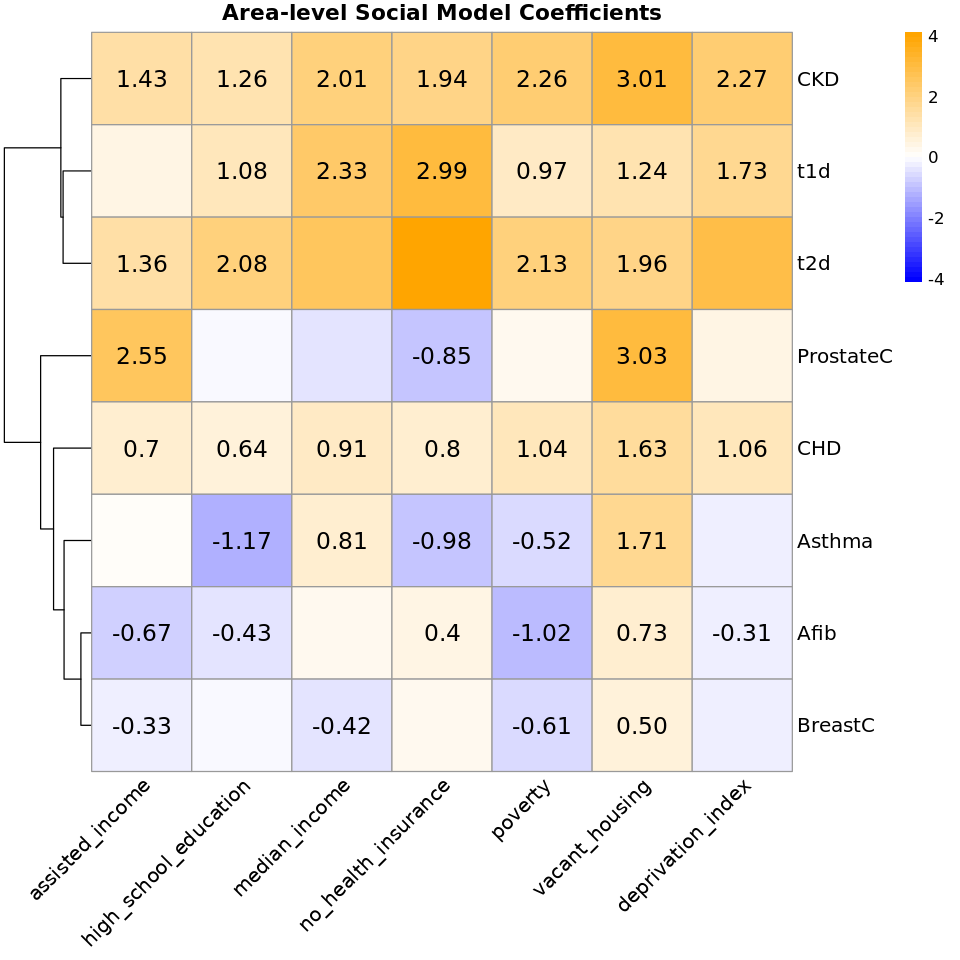

In [40]:
# Step 2: Define a diverging color scale centered at 0
max_abs_value <- max(abs(heatmap_data), na.rm = TRUE)  # Maximum absolute value for symmetric scaling
breaks <- seq(-max_abs_value, max_abs_value, length.out = 51)  # Create breaks for the scale

color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors


# Step 3: Create a clustering heatmap
map<-pheatmap(
  heatmap_data,
  color = color_palette,  # Diverging color scale
  breaks = breaks,  # Center scale at 0
  cluster_rows = TRUE,  # Cluster diseases
  cluster_cols = FALSE,  # Do not cluster columns (respect custom order)
  main = "Area-level Social Model Coefficients",
  fontsize_row = 12,  # Font size for row labels
  fontsize_col = 12,  # Font size for column labels
  display_numbers = heatmap_data_labels,  # Show effect sizes in cells
  number_color = "black",  # Color of the numbers
  number_format = "%.2f",  # Format for numbers in cells
  fontsize_number=14,
  height = 1,  # Increase vertical size of the heatmap
  width=3,
   angle_col = 45  
)

options(repr.plot.width = 8, repr.plot.height = 8)  # Set width and height

# Save the plot (optional)
ggsave("area_sdoh_coefficients_heatmap.png", plot = map, width = 8, height = 8, dpi = 300)

## Interaction heatmap

In [41]:
x_axis_order <- c('PRS*assisted_income', 'PRS*high_school_education', 'PRS*median_income', 
           'PRS*no_health_insurance', 'PRS*poverty', 'PRS*vacant_housing', 'PRS*deprivation_index')


# Step 1: Ensure unique values for each Disease and term combination
all_coefficients_clean <- all_coefficients %>%
  group_by(Disease, term) %>%
  summarize(Effect_Size = mean(Effect_Size, na.rm = TRUE), .groups = "drop")  # Aggregate duplicates by averaging

# Step 2: Reshape data for clustering
heatmap_data <- all_coefficients_clean %>%
  pivot_wider(
    names_from = term,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = Effect_Size  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames

# Ensure all values are numeric and handle NA values
heatmap_data <- heatmap_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
heatmap_data[is.na(heatmap_data)] <- 0  # Replace NA values with 0 (or another placeholder)


heatmap_data <- heatmap_data %>%
  select(all_of(x_axis_order))  # Reorder columns to match the specified list


# Step 2: Verify heatmap data
print(heatmap_data)

          PRS*assisted_income PRS*high_school_education PRS*median_income
Afib               -1.0879567               -0.59354475         0.5807817
Asthma             -0.5236986                0.06243269        -0.7240657
BreastC            -1.5384393               -1.79119632        -0.9533574
CHD                -3.3868787               -2.78641716        -0.5659899
CKD                -3.9670518               -2.95619020        -2.3526306
ProstateC          -0.6467389               -0.66393398         0.2100290
t1d                -1.8908727               -3.39614353        -2.7657357
t2d                -3.8333412               -4.02614842        -2.5536733
          PRS*no_health_insurance PRS*poverty PRS*vacant_housing
Afib                    1.1087158  -0.7409015          0.1591313
Asthma                 -0.4525073  -0.5105530         -2.8313981
BreastC                -1.1189547  -2.4427175          1.5804590
CHD                    -1.4019435  -3.8959794         -2.6963709
CKD      

In [42]:
# Step 1: Ensure unique values for each Disease and term combination
all_coefficients_clean <- all_coefficients %>%
  group_by(Disease, term) %>%
  summarize(
    p_value = mean(p.value, na.rm = TRUE),  # Aggregate p-values for consistency
    .groups = "drop"
  ) 

# Step 2: Reshape data for clustering
pvalue_data <- all_coefficients_clean %>%
  pivot_wider(
    names_from = term,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = p_value  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames


# Ensure all values are numeric and handle NA values
pvalue_data <- pvalue_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
pvalue_data[is.na(pvalue_data)] <- 0  # Replace NA values with 0 (or another placeholder)
pvalue_data<-ifelse(pvalue_data<0.05/56, "**", ifelse(pvalue_data<0.05, "*", " "))
pvalue_data <- as.data.frame(pvalue_data)


pvalue_data <- pvalue_data %>%
  select(all_of(x_axis_order))  # Reorder columns to match the specified list

pvalue_data

,PRS*assisted_income,PRS*high_school_education,PRS*median_income,PRS*no_health_insurance,PRS*poverty,PRS*vacant_housing,PRS*deprivation_index
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Afib,,,,,,,
Asthma,,,,,,*,
BreastC,,*,,,*,,
CHD,**,**,,*,**,*,**
CKD,**,**,*,**,**,*,**
ProstateC,,,,,,,
t1d,,*,,*,,,*
t2d,**,**,**,**,**,,**


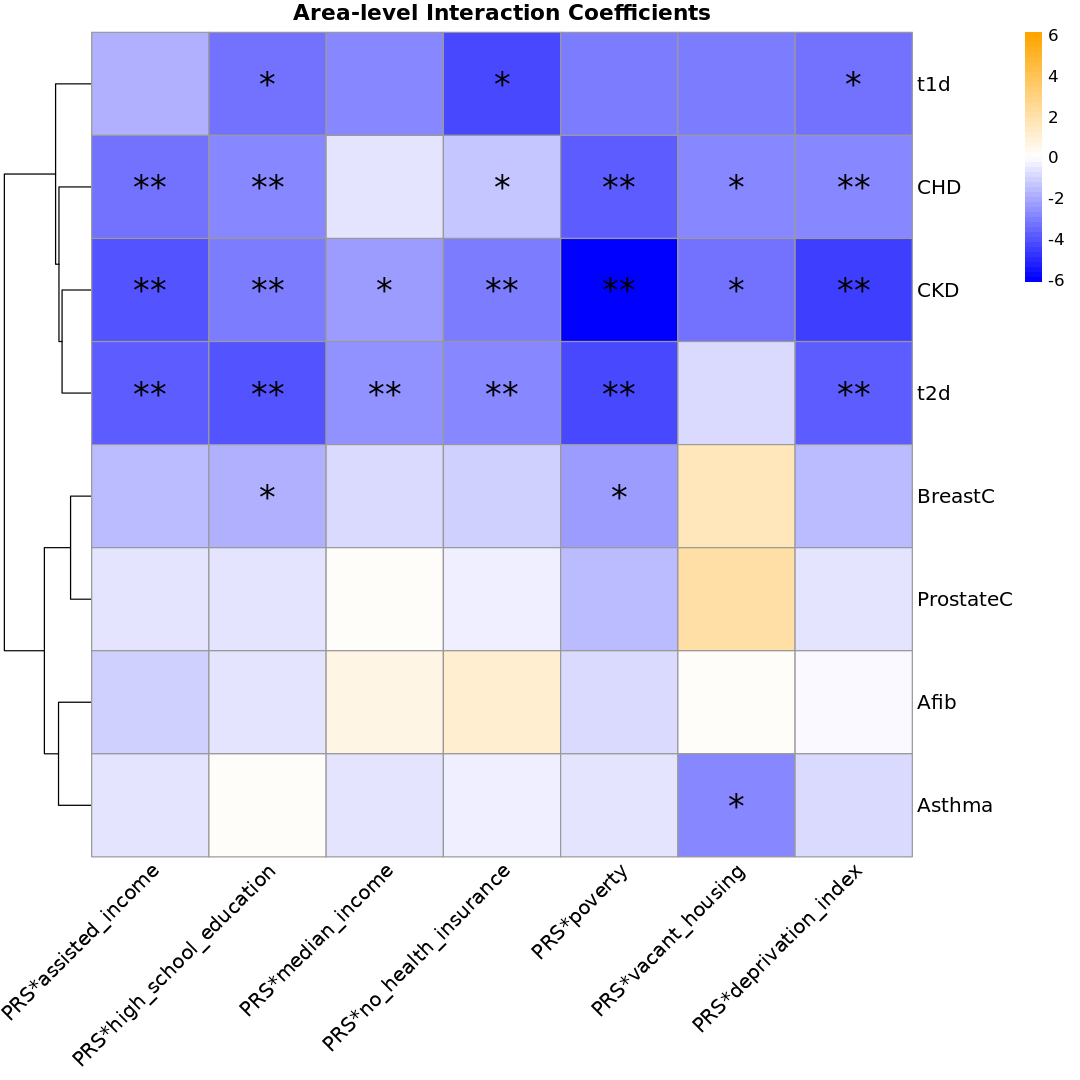

In [45]:
# Step 2: Define a diverging color scale centered at 0
max_abs_value <- max(abs(heatmap_data), na.rm = TRUE)  # Maximum absolute value for symmetric scaling
breaks <- seq(-max_abs_value, max_abs_value, length.out = 51)  # Create breaks for the scale

color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors


# Step 3: Create a clustering heatmap
map<-pheatmap(
  heatmap_data,
  color = color_palette,  # Diverging color scale
  breaks = breaks,  # Center scale at 0
  cluster_rows = TRUE,  # Cluster diseases
  cluster_cols = FALSE,  # Do not cluster columns (respect custom order)
  main = "Area-level Interaction Coefficients",
  fontsize_row = 12,  # Font size for row labels
  fontsize_col = 12,  # Font size for column labels
  display_numbers = pvalue_data,  # Show effect sizes in cells
  number_color = "black",  # Color of the numbers
  number_format = "%.2f",  # Format for numbers in cells
  fontsize_number = 20,
  height = 1,  # Increase vertical size of the heatmap
  width=3,
   angle_col = 45  
)

options(repr.plot.width = 8, repr.plot.height = 8)  # Set width and height

# Save the plot (optional)
ggsave("area_sdoh_interaction_heatmap.png", plot = map, width = 8, height = 8, dpi = 300)